In [1]:
#Goal: practice regex on real Japanese and English data
#Main question: How do trending video titles differ in style between the US and Japan?
#Limitation: the data only contain trending videos and within limited time period: Nov 2017 to Jun 2018. 

In [2]:
import pandas as pd
import re
pd.set_option('display.max_colwidth', None)

In [3]:
df = pd.read_csv("USvideos.csv")

In [4]:
#df.head()

In [5]:
#cleaning date columns 
df["trending_date"] = pd.to_datetime(df["trending_date"], format='%y.%d.%m')
df["publish_time"] = pd.to_datetime(df["publish_time"])

In [6]:
df = df.drop_duplicates(subset='video_id',  keep='last')

In [7]:
df["title"].sample(30, random_state=42)

26349                                                                                           GOT7 Look M/V
20876                                                Jimmy Butler sustains apparent non-contact injury | ESPN
11592                                                      World's smallest cat - Big Cats: Preview - BBC One
11394                                                                         Dazed & Confused - LIVIN Speech
12352                                                                                       Meme Team - Top 5
2967                                                                       SEVDALIZA - HEAR MY PAIN HEAL (4K)
378                                                    SECRETS REVEALED! HOW I LAY MY LACE WIGS! | AALIYAHJAY
17171                                                    The best places to watch a rocket launch in Florida!
17842                                                Hair Stylists React to Trump’s Hair Flapping in the Wind
1987      

In [8]:
#Counting dashes 
df["title"].str.contains(r'\s-\s').value_counts()

title
False    4902
True     1449
Name: count, dtype: int64

In [9]:
#Sample has 17 dashed within 30 samples, that is over 57% of the text, but total only gave 22,8% whic is low 
#[df["title"].str.contains(r'\s-\s')==False].sample(40)
#none of originally given False title seems to have dash, no mistake in regex

In [10]:
#df["title"].sample(30)

In [11]:
#df["title"].sample(30)

In [12]:
#3 different random samples lowed down the number of dashes to 28 out of 90 or 31% 

In [13]:
df['has_dashes'] = df["title"].str.contains(r'\s-\s')

In [14]:
dashes_titles = df["title"].str.contains(r'\s-\s').sum()

In [15]:
#Counting pipe 
df["title"].str.contains(r'\s\|\s').value_counts(normalize = True)

title
False    0.783814
True     0.216186
Name: proportion, dtype: float64

In [16]:
df['has_pipes'] = df["title"].str.contains(r'\s\|\s')

In [17]:
pipes_titles = df["title"].str.contains(r'\s\|\s').sum()

In [18]:
#length of each title 
df['n_char'] = df["title"].str.len()

<Axes: title={'center': 'Number of characters in titles'}, ylabel='Frequency'>

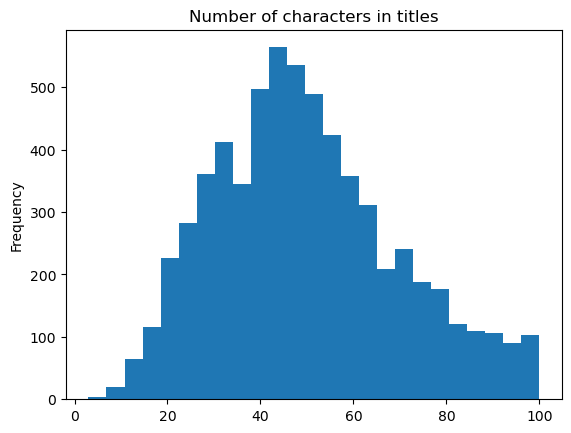

In [19]:
df['n_char'].plot(kind='hist',  bins=25, title='Number of characters in titles')

In [20]:
#Average, min and max title len 
avg_len = df['n_char'].mean().round(2)
min_len = df['n_char'].min()
max_len = df['n_char'].max()

In [21]:
#words full in capital letters 
#df['has_caps_word'] = df['title'].str.contains(r'\b[A-Z]{2,}\b')
#df['n_caps_words'] = df['title'].str.count(r'\b[A-Z]{2,}\b')

In [22]:
#Check if abbsacronyms and cap names are in this list
df['title'].str.extractall(r'(\b[A-Z]{2,}\b)').value_counts().head(50)

0        
HD           139
ESPN          91
MY            86
THE           78
TO            76
DIY           56
NFL           53
MAKEUP        52
NBA           47
SNL           46
OF            37
NEW           37
NBC           36
BBC           34
BTS           33
REACT         33
IN            32
LIVE          32
TV            30
FULL          29
CHALLENGE     28
TBS           27
WIRED         26
WITH          25
IT            25
TIME          25
ME            23
VIDEO         23
OFFICIAL      22
EVER          21
TODAY         21
WE            21
FOR           21
WWHL          21
FOX           21
BEST          20
MV            20
HBO           20
ON            19
AND           19
YOU           19
HOW           18
IS            18
NYC           17
ABC           17
CHRISTMAS     16
US            16
WWE           16
EVERY         16
YIAY          15
Name: count, dtype: int64

In [23]:
#about 44% of the top caps words are acronyms or names
acr = ['HD', 'ESPN', 'DIY', 'NFL', 'NBA', 'SNL', 'NBC', 'BBC', 'TV', 'TBS', 'WIRED', 'WWHL', 'FOX', 'MV', 'HBO', 'NYC', 'ABC', 'WWE', 'YIAY']

In [24]:
#df[df['title'].str.contains(r'\b(?:' + '|'.join(acr) + r')\b')]

In [25]:
#Create a pattern that exclude acr while counting cap words
df['has_caps_word'] = df['title'].str.contains(r'\b(?!(?:' + '|'.join(acr) + r')\b)[A-Z]{2,}\b')
df['n_caps_words'] = df['title'].str.count(r'\b(?!(?:' + '|'.join(acr) + r')\b)[A-Z]{2,}\b')

In [26]:
n_caps_titles = df['title'].str.contains(r'\b(?!(?:' + '|'.join(acr) + r')\b)[A-Z]{2,}\b').sum()

In [27]:
#Testing a sample 
#df[df["title"].str.contains(r'\s[A-Z]*\s')==False].sample(10)

In [28]:
df['title'].str.contains(r'\([^\)]*\)').value_counts()

title
False    5454
True      897
Name: count, dtype: int64

In [29]:
df['has_round'] = df["title"].str.contains(r'\([^\)]*\)')

In [30]:
round_titles = df["title"].str.contains(r'\([^\)]*\)').sum()

In [31]:
df["title"].str.contains(r'\[[^\]]*\]').value_counts()

title
False    6145
True      206
Name: count, dtype: int64

In [32]:
#Testing 
#df[df["title"].str.contains(r'\s\[[^]]*\]\s')==False].sample(30)

In [33]:
df['has_square'] = df["title"].str.contains(r'\[[^\]]*\]')

In [34]:
square_titles = df["title"].str.contains(r'\[[^\]]*\]').sum()

In [35]:
#Count ! per string and in total

In [36]:
df['n_exclaim'] = df['title'].str.count(r'!')
df['has_exclaim'] = df['title'].str.contains(r'!')

In [37]:
exclaim_titles = df['title'].str.contains(r'!').sum()

In [38]:
#Test
#df['title'].iloc[0].count(r'!')

In [39]:
#Count ? 

In [40]:
df['has_question'] = df['title'].str.contains(r'\?')
df['n_question'] = df['title'].str.count(r'\?')

In [41]:
question_titles = df['title'].str.contains(r'\?').sum()

In [42]:
#Count hashtags
df['has_hashtag'] = df['title'].str.contains(r'#\w')
df['n_hashtag'] = df['title'].str.count(r'#\w')

In [43]:
hashtag_titles = df['title'].str.contains(r'#').sum()

In [44]:
#Check for numbers in titles 

In [45]:
df['title'].str.contains(r'[0-9]+').value_counts()

title
False    4687
True     1664
Name: count, dtype: int64

In [114]:
#Checked false sample 
#df[df['title'].str.contains(r'[0-9]+')==False].sample(50)

In [116]:
numbers_titles = df['title'].str.contains(r'[0-9]+').sum()

In [96]:
#Check for emojies
emoji_pat = r'[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F1E6-\U0001F1FF]'
df['has_emoji'] = df['title'].str.contains(emoji_pat)

In [118]:
#Checking samples 
#df[df['title'].str.contains(emoji_pat)==False].sample(50)

In [120]:
emoji_titles = df['title'].str.contains(emoji_pat).sum()

In [163]:
#Finalize the results in the table 
us_counts = {
'has_dashes': dashes_titles, 
'has_pipes': pipes_titles, 
'has_caps_word': n_caps_titles, 
'has_round_ brackets': round_titles, 
'has_square_ brackets': square_titles, 
'has_exclamaition': exclaim_titles, 
'has_question': question_titles, 
'has_hashtag': hashtag_titles, 
'has_numbers': numbers_titles, 
'has_emoji': emoji_titles, 
}

us_counts_table = pd.DataFrame({'Titles': us_counts})
us_counts_table ['Share (%)'] = (us_counts_table['Titles'] / len(df) * 100).round(1)
#us_counts_table  = us_counts_table.sort_values('Titles', ascending=False)

In [165]:
us_counts_table

,Titles,Share (%)
has_dashes,1449,22.8
has_pipes,1373,21.6
has_caps_word,1771,27.9
has_round_ brackets,897,14.1
has_square_ brackets,206,3.2
has_exclamaition,674,10.6
has_question,357,5.6
has_hashtag,119,1.9
has_numbers,1664,26.2
has_emoji,74,1.2


In [167]:
us_length = pd.Series({'average': avg_len, 'minimum': min_len, 'maximum': max_len}, name='n_char')

In [169]:
us_length 

average     49.82
minimum      3.00
maximum    100.00
Name: n_char, dtype: float64

In [171]:
#us_counts_table.to_csv('us_features.csv')